# Section 1: Encoding Hour and Month

In this section, we compare different encoding techniques
for hour and month to improve bike rental demand prediction.


In [1]:
import sys
sys.path.append('../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data import load_hour_data, chronological_split, get_xy

# Load dataset
df = load_hour_data()

# Split data chronologically
train, test = chronological_split(df)

# Separate features and target
X_train, y_train = get_xy(train)
X_test, y_test = get_xy(test)

print("Dataset shape:", df.shape)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Dataset shape: (17379, 17)
Training data: (13003, 12)
Testing data: (4376, 12)


### 1.1 Understanding Cyclic Encoding

Hours follow a circular pattern like a clock. Hour 23 and hour 0
are very close to each other, but raw numerical encoding treats
them as far apart.

Cyclic encoding solves this problem using sine and cosine
transformations.

In [2]:
# Compare hour 23 and hour 0

for hr in [23, 0]:
    sin_value = np.sin(2 * np.pi * hr / 24)
    cos_value = np.cos(2 * np.pi * hr / 24)

    print(f"Hour: {hr}")
    print("Sine:", sin_value)
    print("Cosine:", cos_value)
    print()

Hour: 23
Sine: -0.25881904510252157
Cosine: 0.9659258262890681

Hour: 0
Sine: 0.0
Cosine: 1.0



### 1.2 Visualising Cyclic Encoding

We represent all 24 hours on a circle using sine and cosine.
This shows that hour 23 and hour 0 are neighbours.

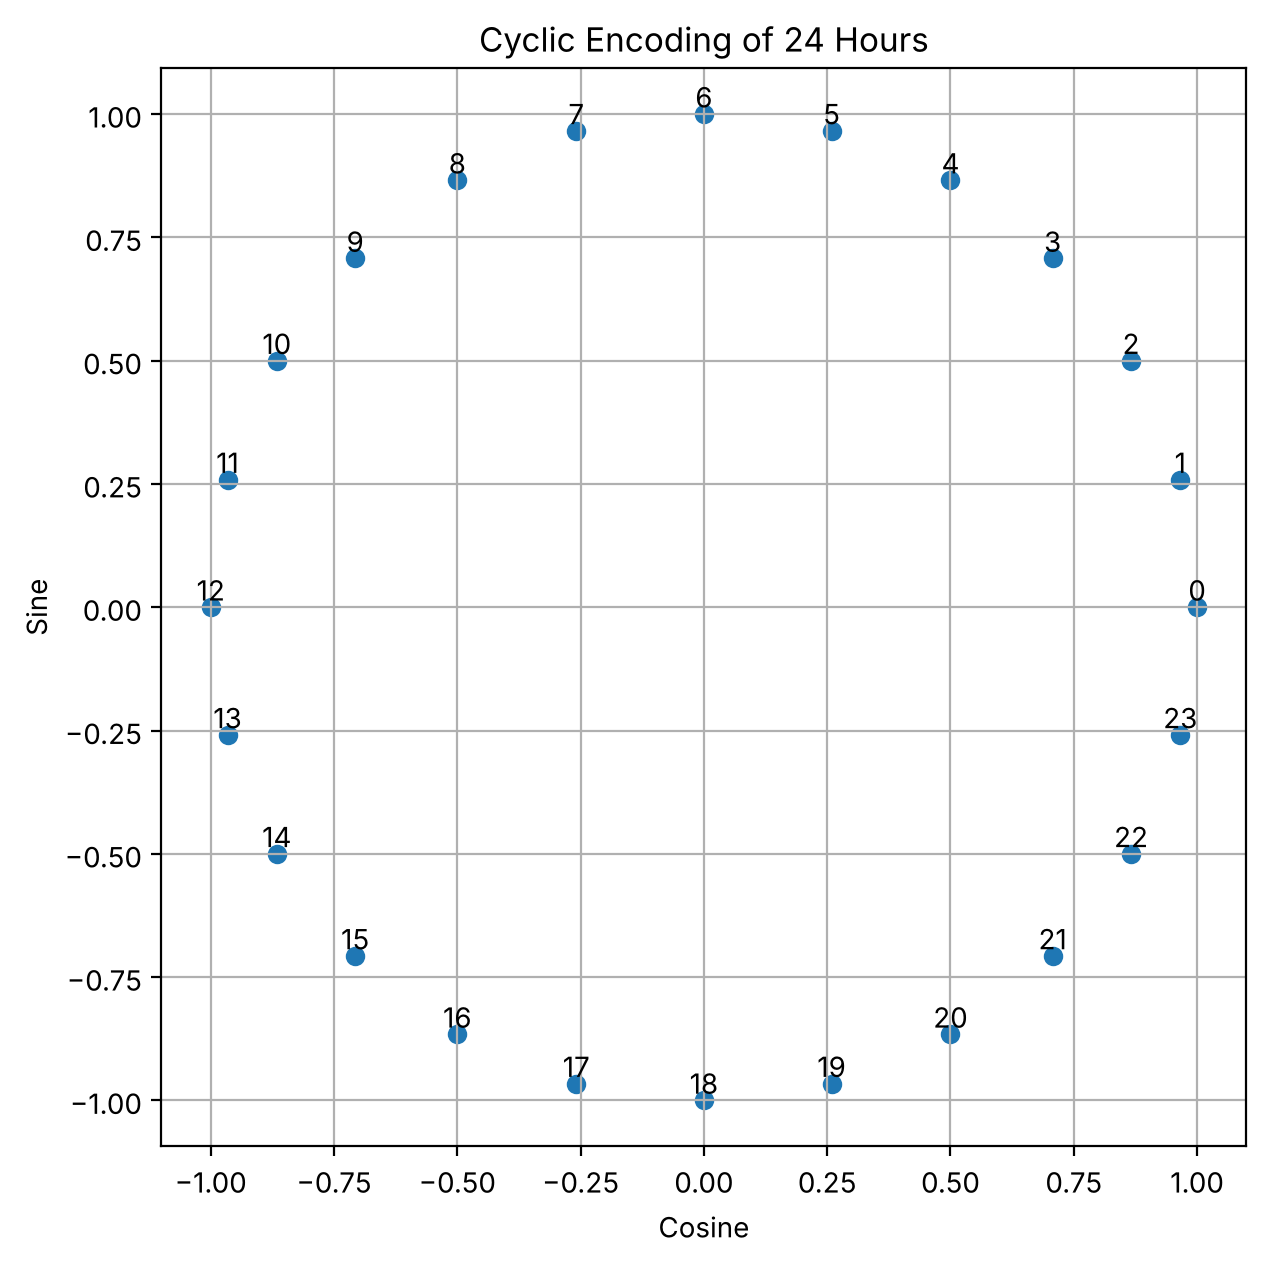

In [3]:
hours = np.arange(24)

hour_sin = np.sin(2 * np.pi * hours / 24)
hour_cos = np.cos(2 * np.pi * hours / 24)

plt.figure(figsize=(7, 7))

plt.scatter(hour_cos, hour_sin)

for hr in hours:
    plt.text(hour_cos[hr], hour_sin[hr], str(hr),
             ha='center', va='bottom')

plt.xlabel("Cosine")
plt.ylabel("Sine")
plt.title("Cyclic Encoding of 24 Hours")
plt.axis("equal")
plt.grid(True)
plt.show()

### 1.3 Comparing Hour Encoding Methods

We compare three encoding methods:

1. Raw Encoding: Treats hour as a normal numerical value.
2. Cyclic Encoding: Uses sine and cosine to represent the circular nature of hours.
3. One-Hot Encoding: Creates a separate column for each hour.

We use Linear Regression and TimeSeriesSplit to compare their performance.

In [4]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Common features used in all three models
common_features = ['yr', 'workingday', 'temp', 'mnth']

# Cyclic encoding function
def cyclic_hour(X):
    X = np.asarray(X, dtype=float)

    return np.hstack([
        np.sin(2 * np.pi * X / 24),
        np.cos(2 * np.pi * X / 24)
    ])

# 1. RAW ENCODING
raw_preprocessor = ColumnTransformer([
    ('hour', 'passthrough', ['hr']),
    ('other', 'passthrough', common_features)
])

# 2. CYCLIC ENCODING
cyclic_preprocessor = ColumnTransformer([
    ('hour', FunctionTransformer(cyclic_hour), ['hr']),
    ('other', 'passthrough', common_features)
])

# 3. ONE-HOT ENCODING
onehot_preprocessor = ColumnTransformer([
    ('hour', OneHotEncoder(handle_unknown='ignore'), ['hr']),
    ('other', 'passthrough', common_features)
])

# Create three pipelines
models = {
    'Raw': Pipeline([
        ('prep', raw_preprocessor),
        ('model', LinearRegression())
    ]),

    'Cyclic': Pipeline([
        ('prep', cyclic_preprocessor),
        ('model', LinearRegression())
    ]),

    'One-Hot': Pipeline([
        ('prep', onehot_preprocessor),
        ('model', LinearRegression())
    ])
}

# Time Series Cross Validation
tscv = TimeSeriesSplit(n_splits=5)

results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=tscv,
        scoring='neg_root_mean_squared_error'
    )

    rmse = -scores

    results.append({
        'Encoding': name,
        'Mean RMSE': rmse.mean(),
        'Std RMSE': rmse.std()
    })

# Display comparison table
hour_results = pd.DataFrame(results)

hour_results = hour_results.sort_values('Mean RMSE')

print("Hour Encoding Comparison:")
display(hour_results.round(3))


Hour Encoding Comparison:


,Encoding,Mean RMSE,Std RMSE
2,One-Hot,112.368,19.884
1,Cyclic,132.489,23.655
0,Raw,145.388,25.270


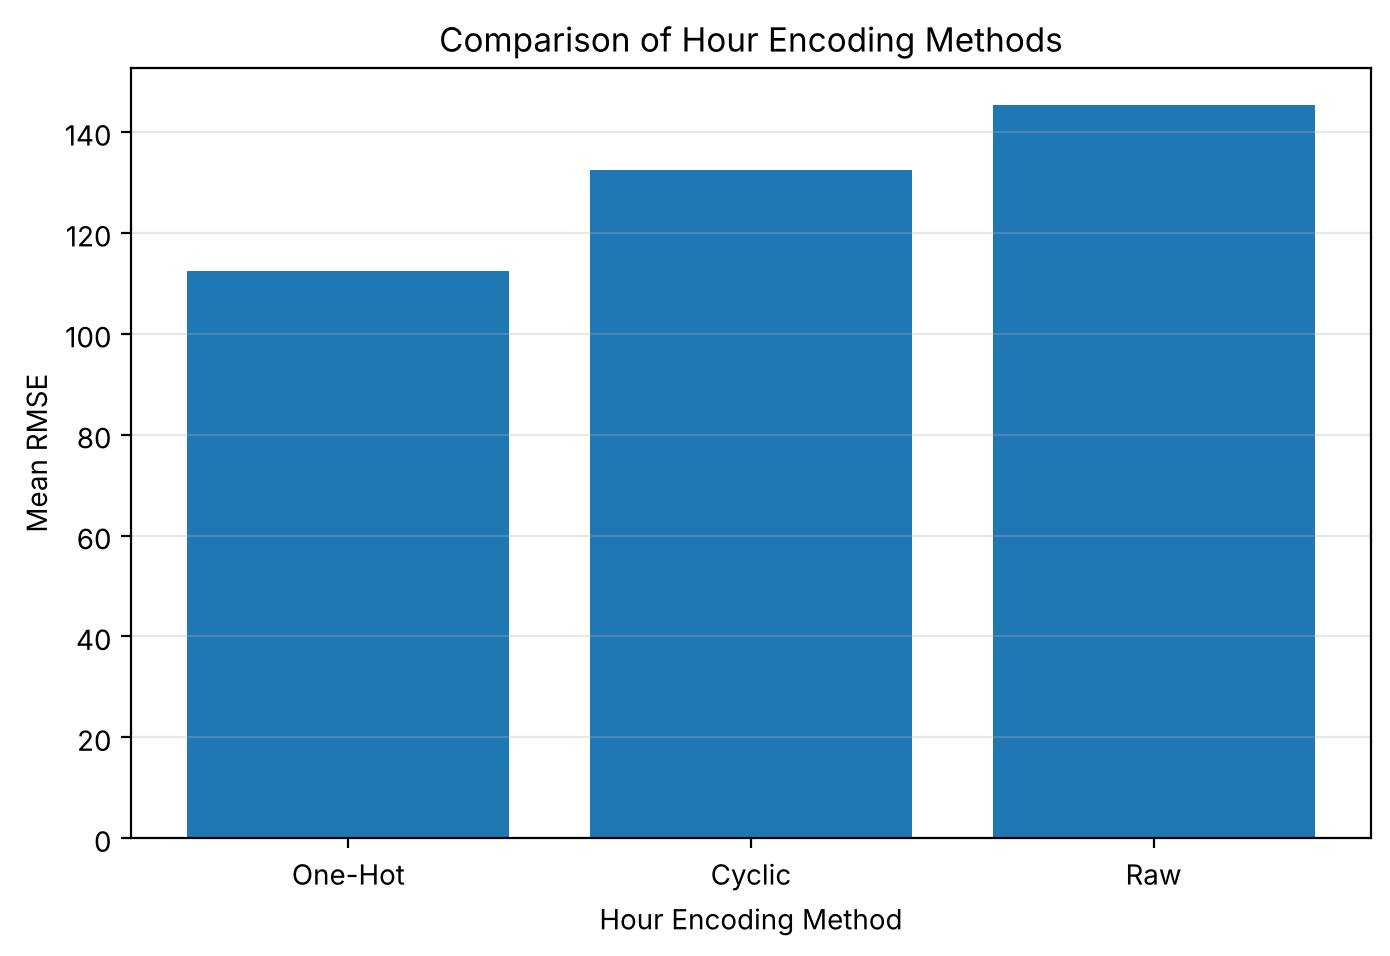

In [5]:
import os
os.makedirs('../results/figures', exist_ok=True)
plt.figure(figsize=(8, 5))

plt.bar(
    hour_results['Encoding'],
    hour_results['Mean RMSE']
)

plt.xlabel("Hour Encoding Method")
plt.ylabel("Mean RMSE")
plt.title("Comparison of Hour Encoding Methods")
plt.grid(axis='y', alpha=0.3)

plt.savefig(
    '../results/figures/hour_encoding_comparison.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

### 1.4 Comparing Month Encoding Methods

We compare two methods of encoding months:

1. Raw Month Encoding
2. Cyclic Month Encoding (Sine and Cosine)

Cyclic encoding represents December and January as neighbouring
months, unlike raw numerical encoding.

We use Linear Regression and TimeSeriesSplit with 5 splits
to compare their performance using RMSE.

In [6]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

# Check that training data has been created
assert 'X_train' in globals() and 'y_train' in globals(), (
    "Run the data-loading and chronological train-test split cells first."
)

# Other features
other_features = ['yr', 'workingday', 'temp']

# Cyclic month encoding
def cyclic_month(X):
    X = np.asarray(X, dtype=float)
    return np.hstack([
        np.sin(2 * np.pi * X / 12),
        np.cos(2 * np.pi * X / 12)
    ])

# Raw month + One-Hot hour
raw_month_prep = ColumnTransformer([
    ('month', 'passthrough', ['mnth']),
    ('hour', OneHotEncoder(handle_unknown='ignore'), ['hr']),
    ('other', 'passthrough', other_features)
])

# Cyclic month + One-Hot hour
cyclic_month_prep = ColumnTransformer([
    ('month', FunctionTransformer(cyclic_month), ['mnth']),
    ('hour', OneHotEncoder(handle_unknown='ignore'), ['hr']),
    ('other', 'passthrough', other_features)
])

# Models
month_models = {
    'Raw Month': Pipeline([
        ('prep', raw_month_prep),
        ('model', LinearRegression())
    ]),
    'Cyclic Month': Pipeline([
        ('prep', cyclic_month_prep),
        ('model', LinearRegression())
    ])
}

# Cross-validation on training data only
tscv = TimeSeriesSplit(n_splits=5)
month_results = []

for name, model in month_models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=tscv,
        scoring='neg_root_mean_squared_error'
    )

    rmse = -scores
    month_results.append({
        'Encoding': name,
        'Mean RMSE': rmse.mean(),
        'Std RMSE': rmse.std()
    })

month_results = pd.DataFrame(month_results)
display(month_results.round(3))


,Encoding,Mean RMSE,Std RMSE
0,Raw Month,112.368,19.884
1,Cyclic Month,113.764,19.319


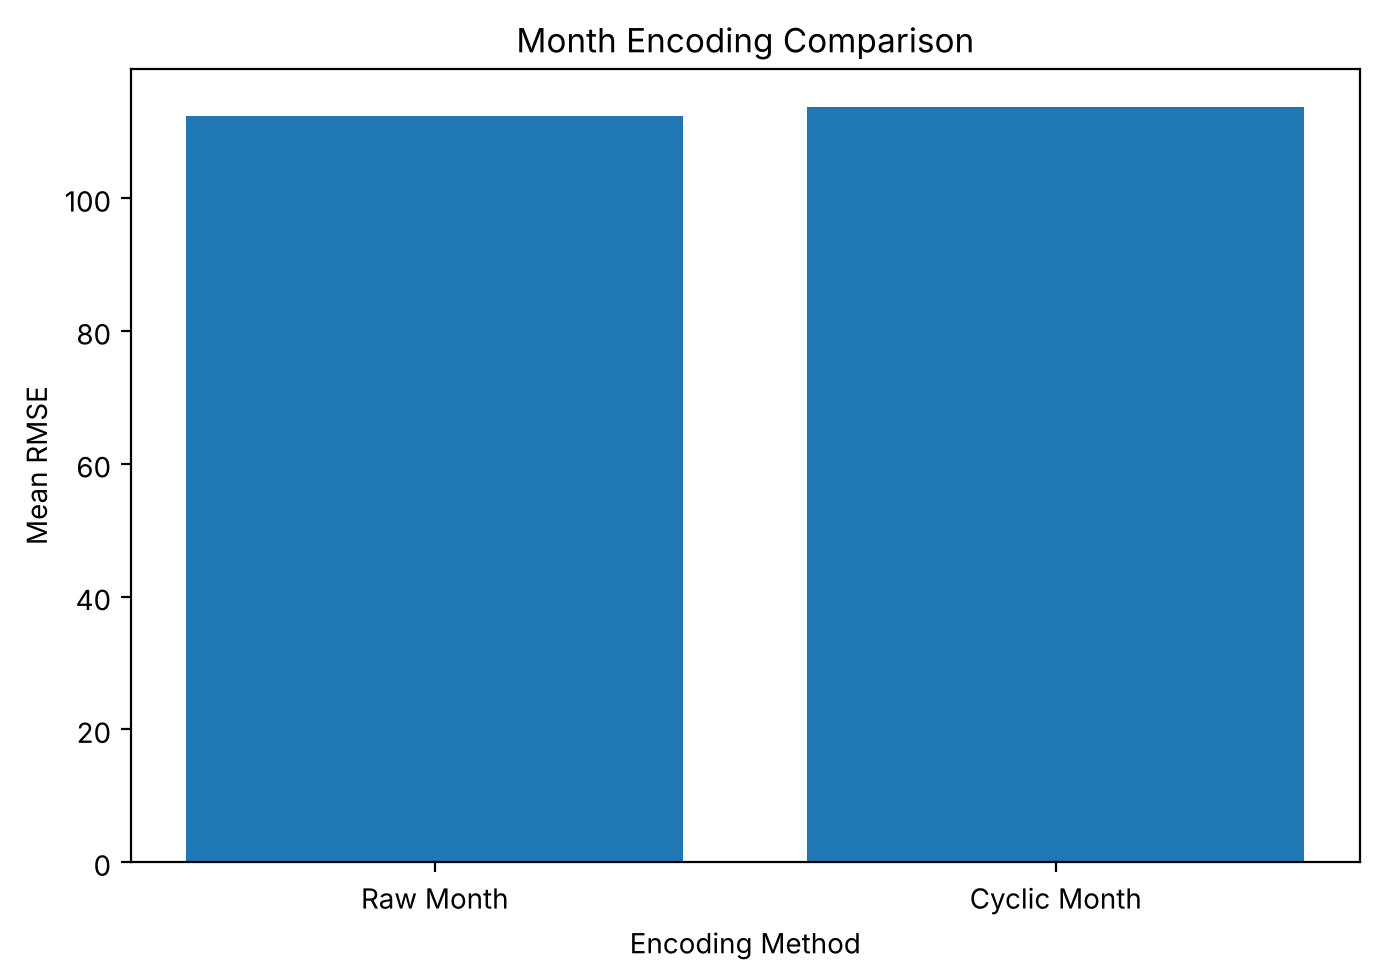

In [7]:

import matplotlib.pyplot as plt
import os

# Get updated month comparison results
plt.figure(figsize=(7, 5))

plt.bar(
    month_results['Encoding'],
    month_results['Mean RMSE']
)

plt.title('Month Encoding Comparison')
plt.xlabel('Encoding Method')
plt.ylabel('Mean RMSE')
plt.tight_layout()

# Save updated graph
os.makedirs('../results/figures', exist_ok=True)
plt.savefig(
    '../results/figures/month_encoding_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


## Section 1.5: Test Set Evaluation (For Information Only)

The following results show the final performance of each encoding method on the test dataset. These results are for information only and are not used to select the best encoding.

In [8]:

from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd

test_results = []

# Evaluate all three hour encoding models
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    test_results.append({
        'Model': f'Hour - {name}',
        'Test RMSE': rmse
    })

# Evaluate both month encoding models
for name, model in month_models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    test_results.append({
        'Model': f'Month - {name} (One-Hot Hour)',
        'Test RMSE': rmse
    })

# Display final test results
test_results = pd.DataFrame(test_results)

display(test_results.round(3))


,Model,Test RMSE
0,Hour - Raw,190.556
1,Hour - Cyclic,169.674
2,Hour - One-Hot,140.771
3,Month - Raw Month (One-Hot Hour),140.771
4,Month - Cyclic Month (One-Hot Hour),140.858


### Conclusion

**Hour encoding.** One-Hot encoding performed best (CV RMSE 112.4), followed by Cyclic (132.5) and Raw (145.4). The ranking is consistent: One-Hot had the lowest RMSE in every one of the 5 folds, and Cyclic beat Raw in every fold. (The std of about 20-25 comes from the folds covering different periods, not from the models disagreeing.) On the test set the order was the same (140.8, 169.7 and 190.6), but the test set was used for information only and not to choose.

One-Hot works best because bike demand has two peaks a day, a morning one and an evening one, mainly from commuting. It gives each hour its own value, so the model can show both peaks. Cyclic encoding is better than Raw because hour 23 and hour 0 become neighbours. However, one sine and cosine pair makes a single smooth wave, so a linear model cannot show two peaks. Raw encoding forces one straight line over the day, which fits worst.

**Month encoding.** Raw month (CV RMSE 112.37) and Cyclic month (113.76) are practically tied. The mean difference is only about 1.4, and the winner changes between folds (Cyclic is better in 2 of the 5 folds and worse in 3). On the test set the gap is only 0.09 (140.77 vs 140.86). So month encoding made no real difference here. Cyclic month is reasonable because December and January become neighbours, but this experiment does not show it is better or worse.

**Decision.** One-Hot is the best hour encoding. For month, either choice is fine.

**Note for the group.** The first version of the final pipeline used cyclic hour. Section 1.6 below tests the linear models with one-hot hour and with one-hot hour x working day, using cross-validation on the training period only.


## Section 1.6: Hour x working day for the linear models

`01-eda.ipynb` showed that working days have two commuter peaks while non-working days have one broad midday peak. A linear model adds one effect per hour, so it cannot give each day type its own daily shape unless we create separate columns for each combination. Here we compare three hour treatments with Linear Regression, using `TimeSeriesSplit` on the **training period only** (the test set is shown for information, not used to choose):

1. Cyclic hour (the first version of the pipeline)
2. One-hot hour
3. One-hot hour x working day

We also compare the two complete pipelines (`build_preprocessor('forest')`, the first version, and `build_preprocessor('linear')`).

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_squared_error
from preprocessing import cyclic_transformer, hour_daytype_encoder, build_preprocessor

others = ['yr', 'workingday', 'temp', 'mnth']   # same other features as section 1.3

variants = {
    'Cyclic hour': ColumnTransformer([('hour', cyclic_transformer(24), ['hr']), ('other', 'passthrough', others)]),
    'One-hot hour': ColumnTransformer([('hour', OneHotEncoder(handle_unknown='ignore'), ['hr']), ('other', 'passthrough', others)]),
    'One-hot hour x working day': ColumnTransformer([('hour', hour_daytype_encoder(), ['hr', 'workingday']), ('other', 'passthrough', others)]),
    'Full pipeline, first version (cyclic hour)': build_preprocessor('forest'),
    'Full pipeline, new (hour x working day)': build_preprocessor('linear'),
}

tscv = TimeSeriesSplit(n_splits=5)
rows = []
for name, prep in variants.items():
    pipe_ = Pipeline([('prep', prep), ('model', LinearRegression())])
    rmse = -cross_val_score(pipe_, X_train, y_train, cv=tscv, scoring='neg_root_mean_squared_error')
    pipe_.fit(X_train, y_train)
    test_rmse = np.sqrt(mean_squared_error(y_test, pipe_.predict(X_test)))
    rows.append({'Variant': name, 'CV mean RMSE': rmse.mean(), 'CV std': rmse.std(), 'Test RMSE (info only)': test_rmse})

interaction_results = pd.DataFrame(rows)
display(interaction_results.round(2))
print('Folds where hour x working day beats one-hot hour:', 
      int((-cross_val_score(Pipeline([('prep', variants['One-hot hour x working day']), ('model', LinearRegression())]), X_train, y_train, cv=tscv, scoring='neg_root_mean_squared_error')
           < -cross_val_score(Pipeline([('prep', variants['One-hot hour']), ('model', LinearRegression())]), X_train, y_train, cv=tscv, scoring='neg_root_mean_squared_error')).sum()), 'of 5')

,Variant,CV mean RMSE,CV std,Test RMSE (info only)
0,Cyclic hour,132.49,23.66,169.67
1,One-hot hour,112.37,19.88,140.77
2,One-hot hour x working day,94.50,18.47,113.50
3,"Full pipeline, first version (cyclic hour)",127.12,22.92,165.73
4,"Full pipeline, new (hour x working day)",86.53,18.51,107.09


Folds where hour x working day beats one-hot hour: 5 of 5


### Conclusion of section 1.6

**Hour treatment.** One-hot hour x working day has the lowest cross-validated RMSE (94.5), compared with one-hot hour (112.4) and cyclic hour (132.5), and it beats plain one-hot hour in all 5 folds. This matches the EDA: working days have two commuter peaks and non-working days one broad midday peak, and a linear model can only show that if each day type gets its own hour columns.

**Full pipelines.** The first version of the pipeline (cyclic hour, `atemp` kept) has a CV RMSE of 127.1 with Linear Regression. The new `build_preprocessor('linear')` pipeline has 86.5. The test RMSE is shown for information only (165.7 for the first version and 107.1 for the new one); it was not used to choose.

**Decision.** Linear, Ridge and Lasso use `build_preprocessor('linear')`. The random forest keeps `build_preprocessor('forest')` (cyclic hour), because section 4.7 of `04-evaluation.ipynb` shows that its one-hot variant makes the forest worse.

## Section 2: Categorical Encoding, Scaling, and the Pipeline

In [10]:
import sys
sys.path.append('../src')

from data import load_hour_data, chronological_split, get_xy
from preprocessing import build_preprocessor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Load and split by time (train before 2012-07-01, test after)
df = load_hour_data()
train, test = chronological_split(df)
X_train, y_train = get_xy(train)
X_test, y_test = get_xy(test)

# Full pipeline for the linear models: preprocessing + model, fitted on TRAIN only
pipe = Pipeline([
    ('prep', build_preprocessor('linear')),
    ('model', LinearRegression())
])

pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
print("Pipeline fitted on train and test predictions generated:", y_pred.shape)

Pipeline fitted on train and test predictions generated: (4376,)


### Pipeline Component Justifications (linear models, `build_preprocessor('linear')`)
- **Hour x working day**: the hour is one-hot encoded separately for working and non-working days (24 x 2 = 48 columns). Section 1.3 showed one-hot hour beats cyclic and raw hour for a linear model, and `01-eda.ipynb` showed that working days and non-working days have different daily shapes. Section 1.6 confirms the combination with cross-validation on the training period.
- **Month**: cyclic (sin/cos with period 12). Section 1.4 showed raw and cyclic month are practically tied, and cyclic keeps December next to January.
- **Season**: One-hot encoded because these are categorical groups with no numeric scale, and it partly overlaps with month.
- **Weathersit**: One-hot encoded because the progression from weather condition 1 to 4 is non-linear. `handle_unknown='ignore'` prevents crashes for unseen categories.
- **Weekday**: One-hot encoded since weekdays lack a natural numeric order for linear models, while binary indicators like `holiday` remain as passthrough (`workingday` is already inside the hour x working-day columns).
- **Temperature, humidity, windspeed**: Scaled using `StandardScaler` so regularization penalties (Ridge/Lasso) weigh all features equally. `atemp` is dropped because it is almost the same measurement as `temp` (correlation 0.99, printed below), so it adds collinearity but no new information.
- **Year (`yr`)**: Kept as-is to preserve the linear growth trend from 2011 to 2012.

The random forest uses `build_preprocessor('forest')` (cyclic hour, `atemp` kept): trees find interactions on their own, and section 4.7 of `04-evaluation.ipynb` shows one-hot hour makes the forest worse.

In [11]:
# 1. Check correlation between temp and atemp (why atemp is dropped for the linear models)
print("--- Correlation between temp and atemp ---")
print(df[['temp', 'atemp']].corr())

# 2. Leakage proof: scaler mean (train only) vs mean of the FULL data
scaler = pipe.named_steps['prep'].named_transformers_['num']
num_cols = ['temp', 'hum', 'windspeed']
print("\n--- Scaler Mean (fitted on train only) ---")
print(scaler.mean_)
print("Mean of the full data (train + test) for comparison:")
print(df[num_cols].mean().values)

# 3. Print output feature names
feature_names = pipe.named_steps['prep'].get_feature_names_out()
print(f"\nTotal output features: {len(feature_names)}")
print(feature_names)

--- Correlation between temp and atemp ---
           temp     atemp
temp   1.000000  0.987672
atemp  0.987672  1.000000

--- Scaler Mean (fitted on train only) ---
[0.48161963 0.6235238  0.1960834 ]
Mean of the full data (train + test) for comparison:
[0.49698717 0.62722884 0.19009761]

Total output features: 70
['hour_daytype__hr_wd_0_0' 'hour_daytype__hr_wd_0_1'
 'hour_daytype__hr_wd_10_0' 'hour_daytype__hr_wd_10_1'
 'hour_daytype__hr_wd_11_0' 'hour_daytype__hr_wd_11_1'
 'hour_daytype__hr_wd_12_0' 'hour_daytype__hr_wd_12_1'
 'hour_daytype__hr_wd_13_0' 'hour_daytype__hr_wd_13_1'
 'hour_daytype__hr_wd_14_0' 'hour_daytype__hr_wd_14_1'
 'hour_daytype__hr_wd_15_0' 'hour_daytype__hr_wd_15_1'
 'hour_daytype__hr_wd_16_0' 'hour_daytype__hr_wd_16_1'
 'hour_daytype__hr_wd_17_0' 'hour_daytype__hr_wd_17_1'
 'hour_daytype__hr_wd_18_0' 'hour_daytype__hr_wd_18_1'
 'hour_daytype__hr_wd_19_0' 'hour_daytype__hr_wd_19_1'
 'hour_daytype__hr_wd_1_0' 'hour_daytype__hr_wd_1_1'
 'hour_daytype__hr_wd_20_0' '